# 03 Train a 2D U-Net (from scratch, PyTorch)

**Before running:** Runtime → Change runtime type → **T4 GPU**. Then Runtime → Run all.

Input: `processed/` (v1) or `processed_v2/` (v2) from notebook 02. Output in `models/` or `models_v2/`: `unet2d_best.pt`, `history.csv`, `test_dice.csv`.

Splits: SAROS `test` cases are never touched until the last cell. SAROS `fold-5` is **validation** (to pick the best epoch). The other folds are **training**.

**Versions.** `VERSION = 'v1'` reproduces the first run (mediastinum and pericardium treated as background). `VERSION = 'v2'` adds a **mediastinum** class (SAROS labels 7 + 9), after the v1 error analysis showed pericardial fat at the diaphragm being mislabelled as abdominal cavity. v2 writes to `*_v2/` folders, so v1 results stay untouched for comparison.

In [ ]:
# setup
from google.colab import drive
drive.mount('/content/drive')

import os, time, random
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F

ROOT = '/content/drive/MyDrive/ct-body-comp'
VERSION = 'v2'   # must match notebook 02
SUFFIX = '' if VERSION == 'v1' else f'_{VERSION}'
PROC = f'{ROOT}/processed{SUFFIX}'
MODELS = f'{ROOT}/models{SUFFIX}'
os.makedirs(MODELS, exist_ok=True)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device, '| GPU:', torch.cuda.get_device_name(0) if device == 'cuda' else 'none (Runtime > Change runtime type > T4 GPU)')

def seed_everything(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything()

Mounted at /content/drive
device: cuda | GPU: Tesla T4


In [ ]:
# settings
CLASS_NAMES = ['background', 'subcutaneous', 'muscle', 'abdominal cavity', 'thoracic cavity', 'bone']
if VERSION == 'v2': CLASS_NAMES = CLASS_NAMES + ['mediastinum']
N_CLASSES = len(CLASS_NAMES)
IGNORE = 255
IMG_SIZE = 256   # train at 256x256 for speed; set 512 for full resolution (~4x slower)
BATCH = 16
EPOCHS = 40
LR = 1e-3
VAL_SPLIT = 'fold-5'                          # one SAROS fold held out for choosing the best epoch

In [ ]:
# load data into memory
index = pd.read_csv(f'{PROC}/index.csv')
index['role'] = np.where(index['set'] == 'test', 'test',
                np.where(index['split'] == VAL_SPLIT, 'val', 'train'))
print(index.groupby('role').agg(cases=('id', 'count'), slices=('n_slices', 'sum')))

def load(role):
    ims, lbs = [], []
    for cid in index.loc[index.role == role, 'id']:
        d = np.load(f'{PROC}/{cid}.npz'); ims.append(d['image']); lbs.append(d['label'])
    return np.concatenate(ims), np.concatenate(lbs)

data = {r: load(r) for r in ['train', 'val', 'test']}

       cases  slices
role                
test       9     140
train     27     438
val       11     190


**Input.** Each slice becomes 2 channels: a soft-tissue window (fat vs muscle) and a wide window (air, lung, bone). Same idea as a radiologist switching window settings.

In [ ]:
# input windows, dataset, augmentation
def hu_to_input(hu):
    """Two 'windows', like a radiologist toggling settings:
       channel 0 = soft tissue window (-200..300 HU): separates fat from muscle
       channel 1 = wide window (-1000..1000 HU): shows air, lung and bone"""
    hu = hu.astype(np.float32)
    soft = (np.clip(hu, -200, 300) + 200) / 500
    wide = (np.clip(hu, -1000, 1000) + 1000) / 2000
    return np.stack([soft, wide]) * 2 - 1          # scaled to [-1, 1]

class SliceDataset(torch.utils.data.Dataset):
    def __init__(self, images, labels, augment=False):
        self.images, self.labels, self.augment = images, labels, augment
    def __len__(self):
        return len(self.images)
    def __getitem__(self, i):
        x = torch.from_numpy(hu_to_input(self.images[i]))           # (2, H, W)
        y = torch.from_numpy(self.labels[i].astype(np.int64))       # (H, W)
        if self.augment:
            if random.random() < 0.5:                                # left-right flip (these classes are roughly symmetric)
                x, y = x.flip(-1), y.flip(-1)
            x = x * random.uniform(0.9, 1.1) + random.uniform(-0.05, 0.05)   # small brightness/contrast jitter
        return x, y

def resize(x, y=None):
    """Resize a batch to IMG_SIZE. Images: smooth (bilinear). Labels: nearest, so class ids stay whole numbers."""
    x = F.interpolate(x, size=(IMG_SIZE, IMG_SIZE), mode='bilinear', align_corners=False)
    if y is None: return x
    y = F.interpolate(y[:, None].float(), size=(IMG_SIZE, IMG_SIZE), mode='nearest')[:, 0].long()
    return x, y

loaders = {r: torch.utils.data.DataLoader(SliceDataset(*data[r], augment=(r == 'train')),
                                          batch_size=BATCH, shuffle=(r == 'train'), num_workers=2)
           for r in data}

**Model.** A classic U-Net: 4 downsampling steps, 4 upsampling steps, skip connections between matching levels. ~7.8 M parameters.

In [ ]:
# the U-Net, written from scratch
class DoubleConv(nn.Module):
    """conv -> batchnorm -> ReLU, twice. The basic building block."""
    def __init__(self, c_in, c_out):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
            nn.Conv2d(c_out, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True))
    def forward(self, x):
        return self.block(x)

class UNet(nn.Module):
    """Encoder shrinks the image and learns WHAT is there; decoder grows it back and learns WHERE.
       Skip connections hand the decoder the fine detail (edges) the encoder saw at each scale."""
    def __init__(self, in_ch=2, n_classes=N_CLASSES, base=32):
        super().__init__()
        ch = [base, base * 2, base * 4, base * 8, base * 16]           # 32, 64, 128, 256, 512
        self.downs = nn.ModuleList([DoubleConv(in_ch, ch[0])] +
                                   [DoubleConv(ch[i], ch[i + 1]) for i in range(4)])
        self.ups = nn.ModuleList([nn.ConvTranspose2d(ch[i + 1], ch[i], 2, stride=2) for i in reversed(range(4))])
        self.up_convs = nn.ModuleList([DoubleConv(ch[i] * 2, ch[i]) for i in reversed(range(4))])
        self.head = nn.Conv2d(ch[0], n_classes, 1)                      # one score per class per pixel
    def forward(self, x):
        skips = []
        for i, down in enumerate(self.downs):
            x = down(x)
            if i < 4:
                skips.append(x); x = F.max_pool2d(x, 2)
        for up, conv, skip in zip(self.ups, self.up_convs, reversed(skips)):
            x = conv(torch.cat([up(x), skip], dim=1))
        return self.head(x)

model = UNet().to(device)
print(f'parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.1f} M')

parameters: 7.8 M


**Loss = cross-entropy + Dice.**
- **Cross-entropy** grades every pixel: stable gradients, but dominated by big classes (background ~50%).
- **Dice** grades every class as a shape: overlap ÷ (predicted area + true area). Each class counts equally regardless of size.
- Together: stability from CE, class balance from Dice. Pixels labelled 255 are ignored by both.

In [ ]:
# the loss = cross-entropy + Dice
def dice_loss(logits, target, eps=1.0):
    """Soft Dice, averaged over the foreground classes (background skipped). Pixels marked 255 are ignored."""
    probs = logits.softmax(1)                                          # (B, C, H, W), each pixel sums to 1
    valid = (target != IGNORE)                                         # (B, H, W)
    onehot = F.one_hot(target.clamp(max=N_CLASSES - 1), N_CLASSES).permute(0, 3, 1, 2).float()
    probs, onehot = probs * valid[:, None], onehot * valid[:, None]
    inter = (probs * onehot).sum((0, 2, 3))                            # overlap per class
    total = probs.sum((0, 2, 3)) + onehot.sum((0, 2, 3))               # predicted + true area per class
    dice = (2 * inter + eps) / (total + eps)
    return 1 - dice[1:].mean()

def loss_fn(logits, target):
    ce = F.cross_entropy(logits, target, ignore_index=IGNORE)
    return ce + dice_loss(logits, target)

**Metric.** Hard Dice per class: 1.0 = perfect overlap, 0 = none.

In [ ]:
# evaluation (hard Dice per class)
@torch.no_grad()
def evaluate(loader, full_res=False):
    """Dice per class over the whole set. full_res=True upsamples predictions back to 512 before scoring."""
    model.eval()
    inter = torch.zeros(N_CLASSES); total = torch.zeros(N_CLASSES)
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(resize(x))
        if full_res:
            logits = F.interpolate(logits, size=y.shape[-2:], mode='bilinear', align_corners=False)
        else:
            _, y = resize(x, y)
        pred = logits.argmax(1); valid = y != IGNORE
        for c in range(N_CLASSES):
            p, t = (pred == c) & valid, (y == c) & valid
            inter[c] += (p & t).sum().item(); total[c] += (p.sum() + t.sum()).item()
    return (2 * inter / total.clamp(min=1)).numpy()

~5 minutes on a T4 at 256×256. Each line prints validation Dice per class; the best epoch is saved to Drive.

In [ ]:
# train
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=EPOCHS * len(loaders['train']))
scaler = torch.amp.GradScaler(enabled=(device == 'cuda'))     # mixed precision: faster on GPU
history, best = [], -1
CKPT = f'{MODELS}/unet2d_best.pt'

for epoch in range(1, EPOCHS + 1):
    model.train(); t0 = time.time(); losses = []
    for x, y in loaders['train']:
        x, y = resize(x.to(device), y.to(device))
        with torch.autocast(device_type=device, enabled=(device == 'cuda')):
            loss = loss_fn(model(x), y)
        opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        losses.append(loss.item())
    val_dice = evaluate(loaders['val'])
    mean_fg = val_dice[1:].mean()
    history.append(dict(epoch=epoch, loss=np.mean(losses), **{CLASS_NAMES[c]: val_dice[c] for c in range(N_CLASSES)}, mean_fg=mean_fg))
    flag = ''
    if mean_fg > best:
        best = mean_fg; torch.save({'model': model.state_dict(), 'epoch': epoch, 'img_size': IMG_SIZE, 'classes': CLASS_NAMES}, CKPT); flag = '  <- best, saved'
    print(f'epoch {epoch:3d} | loss {np.mean(losses):.3f} | val Dice ' +
          ' '.join(f'{CLASS_NAMES[c][:5]} {val_dice[c]:.2f}' for c in range(1, N_CLASSES)) +
          f' | mean {mean_fg:.3f} | {time.time() - t0:.0f}s{flag}')

pd.DataFrame(history).to_csv(f'{MODELS}/history.csv', index=False)

epoch   1 | loss 2.289 | val Dice subcu 0.84 muscl 0.58 abdom 0.07 thora 0.00 bone 0.10 media 0.00 | mean 0.265 | 13s  <- best, saved
epoch   2 | loss 1.896 | val Dice subcu 0.93 muscl 0.70 abdom 0.63 thora 0.11 bone 0.73 media 0.00 | mean 0.516 | 8s  <- best, saved
epoch   3 | loss 1.621 | val Dice subcu 0.94 muscl 0.81 abdom 0.80 thora 0.68 bone 0.78 media 0.00 | mean 0.669 | 8s  <- best, saved
epoch   4 | loss 1.403 | val Dice subcu 0.94 muscl 0.72 abdom 0.79 thora 0.90 bone 0.77 media 0.00 | mean 0.687 | 8s  <- best, saved
epoch   5 | loss 1.216 | val Dice subcu 0.97 muscl 0.79 abdom 0.83 thora 0.93 bone 0.83 media 0.00 | mean 0.724 | 9s  <- best, saved
epoch   6 | loss 1.037 | val Dice subcu 0.95 muscl 0.81 abdom 0.83 thora 0.96 bone 0.84 media 0.02 | mean 0.737 | 8s  <- best, saved
epoch   7 | loss 0.877 | val Dice subcu 0.96 muscl 0.83 abdom 0.89 thora 0.97 bone 0.81 media 0.31 | mean 0.794 | 9s  <- best, saved
epoch   8 | loss 0.695 | val Dice subcu 0.97 muscl 0.90 abdom 0.94 t

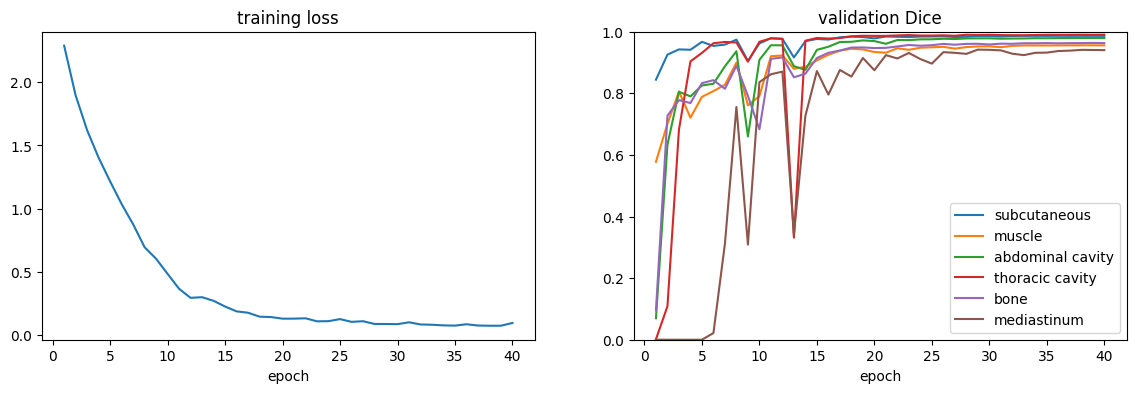

In [ ]:
# learning curves
h = pd.DataFrame(history)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(h.epoch, h.loss); ax[0].set_title('training loss'); ax[0].set_xlabel('epoch')
for c in CLASS_NAMES[1:]: ax[1].plot(h.epoch, h[c], label=c)
ax[1].set_title('validation Dice'); ax[1].set_xlabel('epoch'); ax[1].set_ylim(0, 1); ax[1].legend()
plt.show()

**The real result.** First time the test cases are used. Predictions are upsampled to 512×512 before scoring.

In [ ]:
# final score on the held-out TEST set (best checkpoint, full 512 resolution)
model.load_state_dict(torch.load(CKPT, map_location=device)['model'])
test_dice = evaluate(loaders['test'], full_res=True)
print(f"best epoch: {torch.load(CKPT, map_location=device)['epoch']}")
for c in range(1, N_CLASSES): print(f'{CLASS_NAMES[c]:18s} Dice {test_dice[c]:.3f}')
print(f"{'mean (foreground)':18s} Dice {test_dice[1:].mean():.3f}")
pd.DataFrame({'class': CLASS_NAMES[1:], 'test_dice': test_dice[1:]}).to_csv(f'{MODELS}/test_dice.csv', index=False)

best epoch: 38
subcutaneous       Dice 0.979
muscle             Dice 0.946
abdominal cavity   Dice 0.977
thoracic cavity    Dice 0.983
bone               Dice 0.936
mediastinum        Dice 0.940
mean (foreground)  Dice 0.960


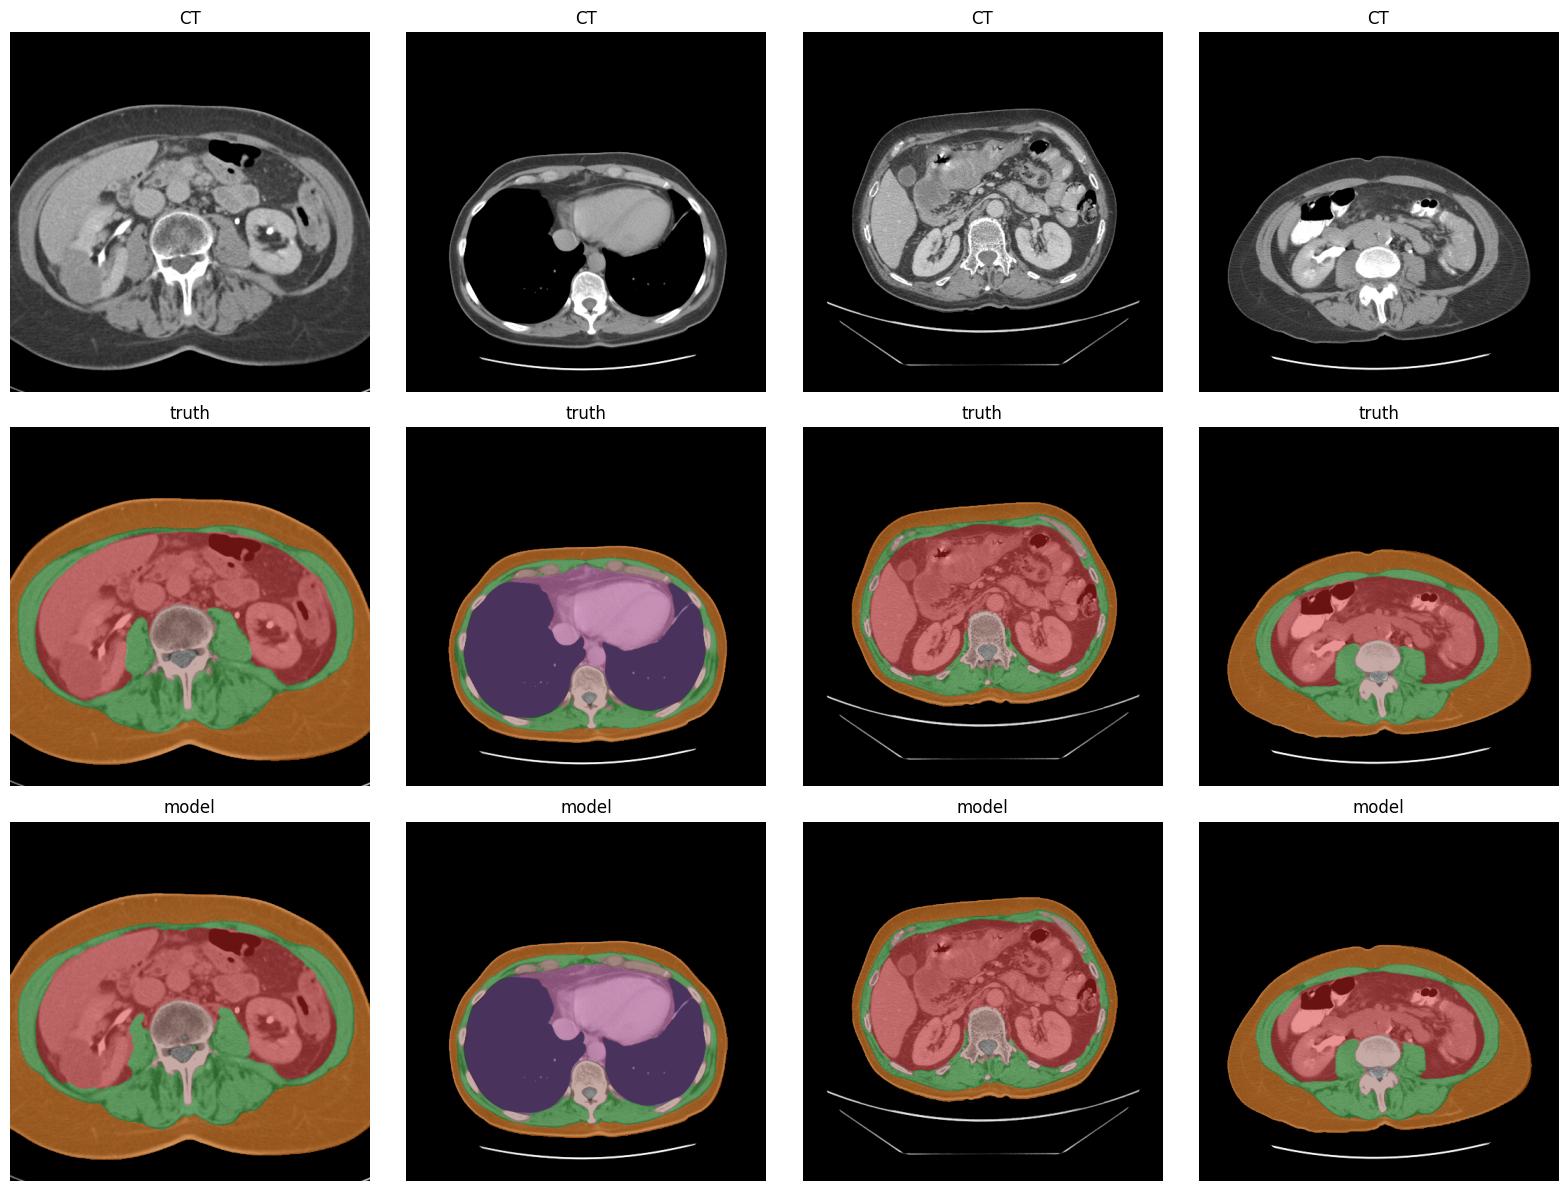

In [ ]:
# look at predictions vs truth on test slices
@torch.no_grad()
def predict(hu):
    model.eval()
    x = torch.from_numpy(hu_to_input(hu))[None].to(device)
    logits = F.interpolate(model(resize(x)), size=hu.shape, mode='bilinear', align_corners=False)
    return logits.argmax(1)[0].cpu().numpy()

ims, lbs = data['test']
pick = np.random.default_rng(1).choice(len(ims), size=min(4, len(ims)), replace=False)
fig, axes = plt.subplots(3, len(pick), figsize=(4 * len(pick), 12))
for k, i in enumerate(pick):
    show = np.clip(ims[i], -200, 250); pred = predict(ims[i])
    axes[0, k].imshow(show, cmap='gray'); axes[0, k].set_title('CT')
    axes[1, k].imshow(show, cmap='gray'); axes[1, k].imshow(np.ma.masked_where((lbs[i] == 0) | (lbs[i] == IGNORE), lbs[i]), cmap='tab10', vmin=0, vmax=9, alpha=0.5); axes[1, k].set_title('truth')
    axes[2, k].imshow(show, cmap='gray'); axes[2, k].imshow(np.ma.masked_where(pred == 0, pred), cmap='tab10', vmin=0, vmax=9, alpha=0.5); axes[2, k].set_title('model')
for a in axes.ravel(): a.axis('off')
plt.tight_layout(); plt.show()